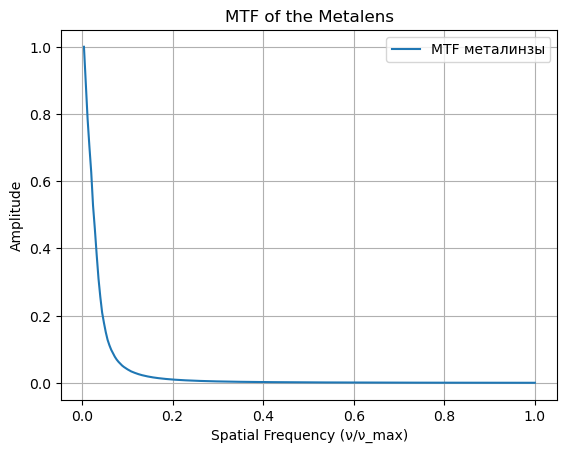

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fftpack import fft2, fftshift
from scipy.special import j1

# Параметры линзы
wavelength = 4.25e-6  # мкм
focal_length = 10e-3  # мм
D = 5e-3  # мкм (диаметр линзы)
N = 500  # Размер сетки

# Пространственные координаты
x_max = 1.22 * wavelength * focal_length / D
x = np.linspace(-x_max, x_max, N)
y = np.linspace(-x_max, x_max, N)
X, Y = np.meshgrid(x, y)
r = np.sqrt(X**2 + Y**2)

# Интенсивность Эйри
k = 2 * np.pi / wavelength
I = 4 * (j1(k * r) / (k * r)) ** 2
I[np.isnan(I)] = 1  # Исправляем деление на 0

# # Нормируем
# I /= np.sum(I)

# 2D FFT и нормализация
fft_field = np.abs(fftshift(fft2(I)))
fft_field /= np.max(fft_field)  # Нормализация

# Построение 1D MTF (усреднение по углам)
center = N // 2
radius = np.linspace(0, center, center)
mtf_1d = np.zeros_like(radius)

for i, r in enumerate(radius.astype(int)):
    mask = np.sqrt((np.arange(N) - center)**2 + (np.arange(N)[:, None] - center)**2) < r
    mtf_1d[i] = np.mean(fft_field[mask])

# Пространственная частота (нормированная)
spatial_freq = np.linspace(0, 1, len(mtf_1d))

# Построение графика MTF
plt.plot(spatial_freq, mtf_1d, label="MTF металинзы")
plt.xlabel("Spatial Frequency (ν/ν_max)")
plt.ylabel("Amplitude")
plt.title("MTF of the Metalens")
plt.grid()
plt.legend()
plt.show()

In [14]:
I

array([[0.00019409, 0.00020408, 0.00021358, ..., 0.00021358, 0.00020408,
        0.00019409],
       [0.00020408, 0.00021362, 0.00022258, ..., 0.00022258, 0.00021362,
        0.00020408],
       [0.00021358, 0.00022258, 0.00023095, ..., 0.00023095, 0.00022258,
        0.00021358],
       ...,
       [0.00021358, 0.00022258, 0.00023095, ..., 0.00023095, 0.00022258,
        0.00021358],
       [0.00020408, 0.00021362, 0.00022258, ..., 0.00022258, 0.00021362,
        0.00020408],
       [0.00019409, 0.00020408, 0.00021358, ..., 0.00021358, 0.00020408,
        0.00019409]])

In [18]:
I.shape

(500, 500)

In [19]:
I[250]

array([5.83273608e-04, 6.21992293e-04, 6.57581983e-04, 6.89490386e-04,
       7.17208387e-04, 7.40278774e-04, 7.58304404e-04, 7.70955678e-04,
       7.77977184e-04, 7.79193413e-04, 7.74513410e-04, 7.63934298e-04,
       7.47543567e-04, 7.25520076e-04, 6.98133730e-04, 6.65743780e-04,
       6.28795758e-04, 5.87817049e-04, 5.43411130e-04, 4.96250530e-04,
       4.47068579e-04, 3.96650043e-04, 3.45820747e-04, 2.95436314e-04,
       2.46370170e-04, 1.99500965e-04, 1.55699583e-04, 1.15815925e-04,
       8.06656443e-05, 5.10170407e-05, 2.75783000e-05, 1.09852832e-05,
       1.79005626e-06, 4.50350300e-07, 7.32013274e-06, 2.26414582e-05,
       4.65377541e-05, 7.90086791e-05, 1.19926674e-04, 1.69035302e-04,
       2.25949454e-04, 2.90157466e-04, 3.61025173e-04, 4.37801899e-04,
       5.19628338e-04, 6.05546283e-04, 6.94510093e-04, 7.85399800e-04,
       8.77035696e-04, 9.68194239e-04, 1.05762508e-03, 1.14406901e-03,
       1.22627652e-03, 1.30302691e-03, 1.37314737e-03, 1.43553212e-03,
      

In [21]:
np.min(I)

8.488222140642884e-14